In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "custseg").exists():   # project root = folder that holds the package
    if ROOT == ROOT.parent:
        raise RuntimeError("run the notebook from inside the project folder")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
from custseg import config, db
img = lambda p, w=900: display(Image(filename=str(ROOT / p), width=w))

# 06 · Experiment 3 — Behavioural clustering

In [2]:
pd.read_csv(ROOT / '07_customer_segmentation/results/feature_screening.csv')

,feature,group,decision,rule
0,recency_days,Transaction Behavior,keep,passes missing / variance / correlation screens
1,frequency,Transaction Behavior,keep,passes missing / variance / correlation screens
2,monetary,Transaction Behavior,keep,passes missing / variance / correlation screens
3,avg_order_value,Transaction Behavior,drop,|Spearman rho| = 0.99 with monetary (> 0.8)
4,avg_purchase_interval_days,Transaction Behavior,drop,undefined for 97.0% of customers (> 50%)
5,std_purchase_interval_days,Transaction Behavior,drop,undefined for 99.8% of customers (> 50%)
6,avg_items_per_order,Transaction Behavior,keep,passes missing / variance / correlation screens
7,n_categories,Product Behavior,keep,passes missing / variance / correlation screens
8,n_unique_products,Product Behavior,keep,passes missing / variance / correlation screens
9,top_category_spend_ratio,Product Behavior,drop,|Spearman rho| = 0.88 with n_categories (> 0.8)


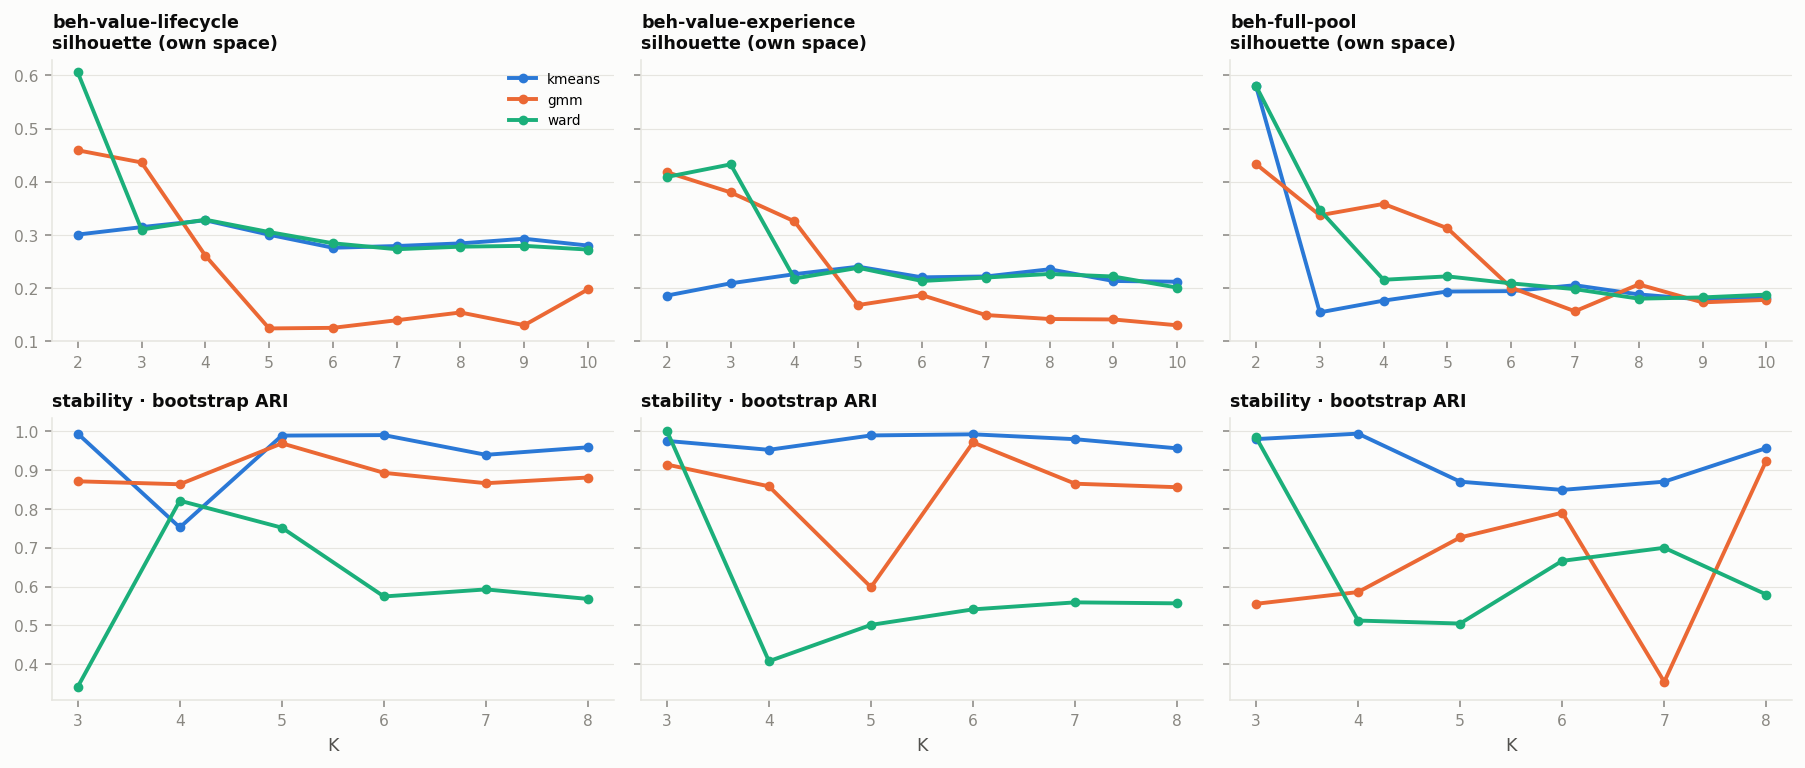

In [3]:
img('07_customer_segmentation/figures/e3_behavioural_k_selection.png')

In [4]:
pd.read_csv(ROOT / '07_customer_segmentation/results/dbscan_results.csv')[['run_id','eps','n_clusters','noise_share','silhouette']].round(3)

,run_id,eps,n_clusters,noise_share,silhouette
0,E3-beh-value-lifecycle-dbscan-sample0,0.483,13,0.072,0.090
1,E3-beh-value-lifecycle-dbscan-sample1,0.484,10,0.067,0.087
2,E3-beh-value-lifecycle-dbscan-sample2,0.484,13,0.072,0.079
3,E3-beh-value-experience-dbscan-sample0,1.301,6,0.049,0.261
4,E3-beh-value-experience-dbscan-sample1,1.294,5,0.052,0.282
5,E3-beh-value-experience-dbscan-sample2,1.281,6,0.051,0.273
6,E3-beh-full-pool-dbscan-sample0,2.553,5,0.057,0.357
7,E3-beh-full-pool-dbscan-sample1,2.513,5,0.058,0.353
8,E3-beh-full-pool-dbscan-sample2,2.527,5,0.053,0.345
